# Lab 5: Introducing GeoAI
In the words of the developers themselves:
"GeoAI is a comprehensive Python package designed to bridge artificial intelligence (AI) and geospatial data analysis, providing researchers and practitioners with intuitive tools for applying machine learning techniques to geographic data. The package offers a unified framework for processing satellite imagery, aerial photographs, and vector data using state-of-the-art deep learning models. GeoAI integrates popular AI frameworks including PyTorch, Transformers, PyTorch Segmentation Models, and specialized geospatial libraries like torchange, enabling users to perform complex geospatial analyses with minimal code."
- [GeoAI 2025](https://opengeoai.org/)


The aim of the this lab is take the knowldege of fundamental mechanics in both satellite data and AI that you have this far gained- and apply them via the bridge that GeoAI provides.

This lab is a modified version of the following tutorial:
- [GeoAI Workshop 2025](https://www.youtube.com/watch?v=jdK-cleFUkc&ab_channel=OpenGeospatialSolutions)


# Task 1: mapping surface water with S2
We start by installing the required package and setting CoLab to run on a GPU (until now, we have been running all our code on a CPU).

In [1]:
# Install ｜ 安装 geoai（本机已装则秒过）
!pip install "geoai-py" --quiet

In [2]:
# Import ｜ 导入
import geoai                                         # GeoAI 主包（封装了整套分割工作流）
import os                                            # 路径与环境变量
import matplotlib.pyplot as plt                      # 自加：报告静态图用
os.makedirs('lab5_figs', exist_ok=True)              # 自加：报告用图目录
os.makedirs('lab5_data', exist_ok=True)              # 自加：数据目录（geoai.download_file 不会自建父目录，Kaggle 上踩过）
import torch                                         # 自加：确认 GPU 在位
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only')        # 打印设备

GPU: Tesla T4


To use GPU, please click the "Runtime" menu and select "Change runtime type". Then select "T4 GPU" from the dropdown menu. GPU acceleration is highly recommended for training deep learning models, as it can reduce training time from hours to minutes.

If you are running this lab on your own laptop, follow the installation instructions linked below in order to ensure that GPU and subsequent CUDA usage is connected up correctly [people using Colab, no need to do so]:
- https://opengeoai.org/installation/

Next, we will get the training data. In this case, GeoAI have linked to the work of Xin Luo who has prepped the [Earth Surface Water](https://zenodo.org/records/5205674#.Y4iEFezP1hE) Dataset from Zenodo, which contains Sentinel-2 imagery with 6 spectral bands and corresponding water masks. This is a high quality dataset that is a good example of 'ready to go' data.



In [3]:
# Access the data ｜ 下载训练数据（HuggingFace 上的 Earth Surface Water 数据集）
url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/dset-s2.zip"               # 数据地址
data_dir = geoai.download_file(url, output_path="lab5_data/dset-s2.zip")         # 下载并自动解压（本机放 lab5_data/，已存在则跳过）

As ever, we will use the training images and masks to train our model, then evaluate performance on the completely independent validation set.

In [4]:
images_dir = f"{data_dir}/dset-s2/tra_scene"         # 训练场景（多幅 6 波段 S2 大图）
masks_dir = f"{data_dir}/dset-s2/tra_truth"          # 训练真值（水体掩膜）
tiles_dir = f"{data_dir}/dset-s2/tiles"              # 切片输出目录

We'll create smaller training tiles from the large GeoTIFF images. Note that we have multiple Sentinel-2 scenes in the training and validation sets, we will use the [GeoAI] export_geotiff_tiles_batch function to export tiles from each scene.

In [5]:
result = geoai.export_geotiff_tiles_batch(           # 把大图批量切成小片
    images_folder=images_dir,                        # 输入影像目录
    masks_folder=masks_dir,                          # 输入真值目录
    output_folder=tiles_dir,                         # 输出目录（images/ 与 masks/）
    tile_size=512,                                   # 每片 512×512 像素
    stride=128,                                      # 步长 128 → 相邻片重叠 384（一景切出很多片）
    quiet=True,                                      # 不刷屏
)

**Q1**: With a tile_size of 512, what is the area in m2 covered by a single tile?

__ANSWER1_PLACEHOLDER__

Now we'll train a semantic segmentation model specifically for **6-channel** Sentinel-2 imagery. The key difference from our previous model is the input channel configuration.

Important parameters to note:
- num_channels=6: Accommodate the 6 Sentinel-2 spectral bands (Blue, Green, Red, NIR, SWIR1, SWIR2)
- Architecture is a U-Net + ResNet34: these are proven effective for multispectral imagery


Let's train the model using the Sentinel-2 tiles:

**Q2**: Explain why using U-Net and ResNet34 together is a good choice when working with multi-spectral imagery.

__ANSWER2_PLACEHOLDER__

In [6]:
geoai.train_segmentation_model(                      # 训练语义分割模型（模板设置：3 轮演示）
    images_dir=f"{tiles_dir}/images",                # 训练切片
    labels_dir=f"{tiles_dir}/masks",                 # 训练标签
    output_dir=f"{tiles_dir}/unet_models",           # 模型输出目录
    architecture="unet",                             # U-Net 解码结构
    encoder_name="resnet34",                         # ResNet34 编码器
    encoder_weights="imagenet",                      # ImageNet 预训练权重起步
    num_channels=6,                                  # 6 个输入通道（S2 六波段）
    num_classes=2,  # background and water ｜ 两类：背景/水
    batch_size=32,                                   # 批大小
    num_epochs=3,  # training for 3 epochs to save time, in practice you should train for more epochs ｜ 演示只 3 轮
    learning_rate=0.001,                             # 学习率（Q3 考点）
    val_split=0.2,                                   # 两成切片当验证
    num_workers=0,                                   # 自加：Windows 上多进程 DataLoader 易卡死，显式用 0
    verbose=True,                                    # 打印过程
)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

**Q3**: What is the learning_rate and what is the likely effect that reducing it will have on your model?

__ANSWER3_PLACEHOLDER__

This model took me 7 to 10 minutes to run on the GPU. If it is taking you more than that, check that you are not still stuck using a CPU (it will take a LOT longer if on a CPU).

With one line of code, we can now take a look at the model performance:

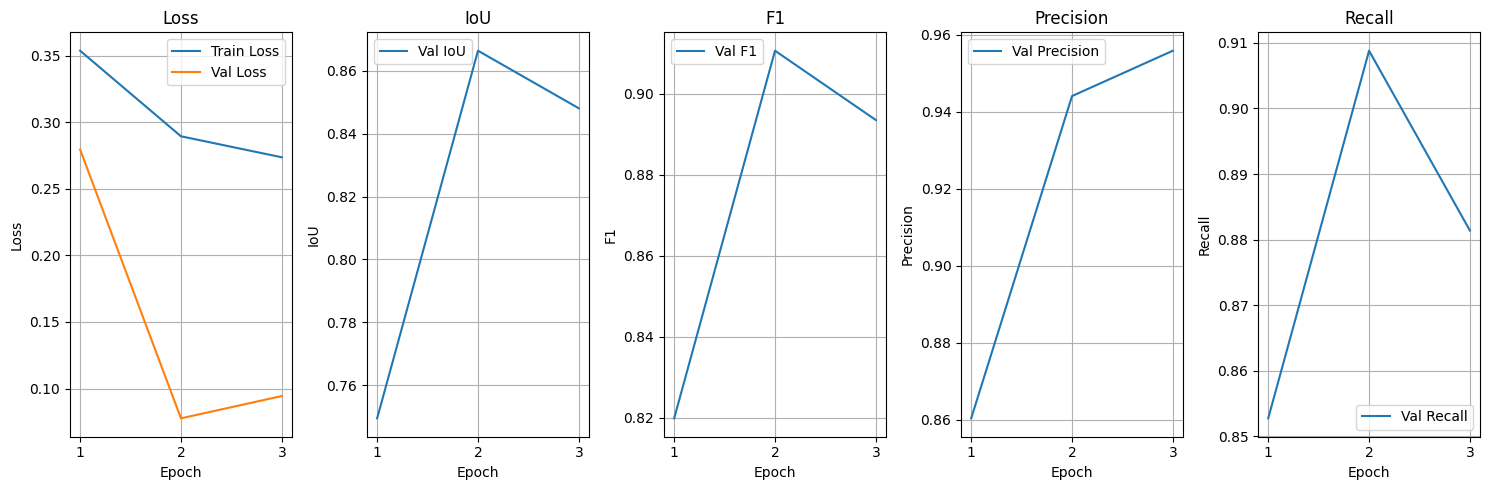

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.353799,0.279544,0.749476,0.819833,0.860308,0.852731
1,2,0.289500,0.077586,0.866383,0.910659,0.944055,0.908811
2,3,0.273721,0.094349,0.848072,0.893531,0.955839,0.881377


In [7]:
# Performance statistics ｜ 画训练指标曲线（3 轮版）
geoai.plot_performance_metrics(
    history_path=f"{tiles_dir}/unet_models/training_history.pth",# 训练历史文件
    figsize=(15, 5),                                 # 画幅
    verbose=True,                                    # 同时打印数值
    save_path='lab5_figs/fig_t1_metrics_e3.png',     # 自加：存盘
)

**Q4**: Increase the number of training epochs to 10 (this will take some time, so maybe come back to this question later if need be). Present the resulting graphs of performance metrics in a figure and interpret the results for a technical audience (describe the training that has occured and make reccomendations for future training/use of the model). As always, figures should be of publication quality.

**（自加）Q4 实现**：按题目要求把训练轮数提到 10，输出到独立目录 `unet_models_e10`（保留 3 轮版便于对照），并出指标图。

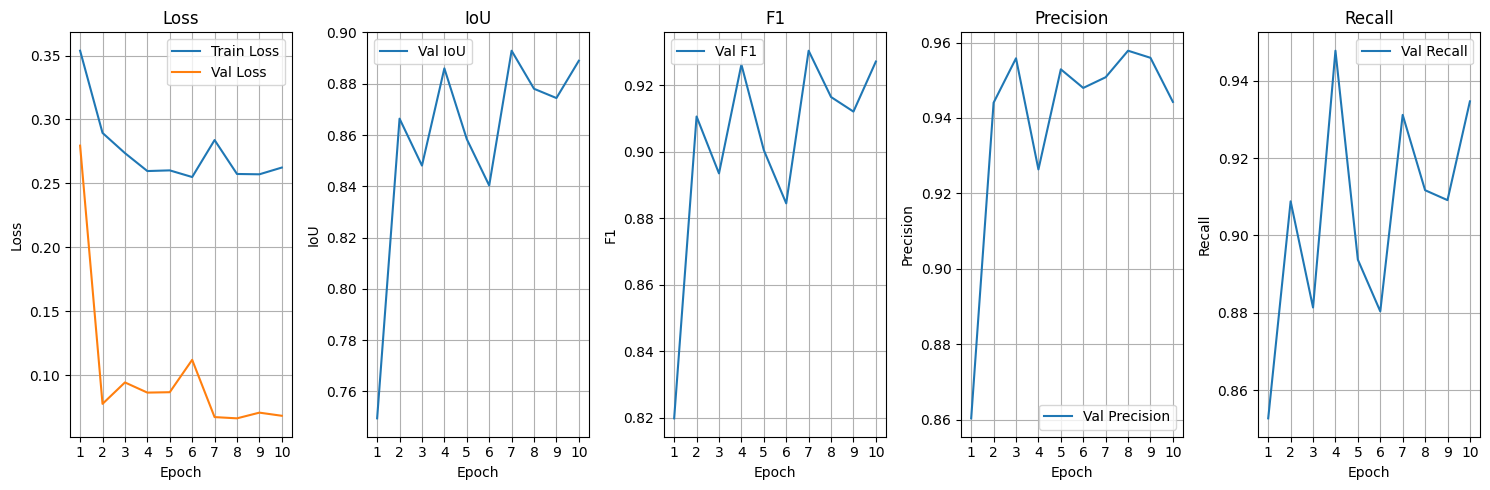

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.353799,0.279544,0.749476,0.819833,0.860308,0.852731
1,2,0.289500,0.077586,0.866383,0.910659,0.944055,0.908811
2,3,0.273721,0.094349,0.848072,0.893531,0.955839,0.881377
3,4,0.259680,0.086390,0.885992,0.926314,0.926347,0.947730
4,5,0.260204,0.086700,0.858410,0.900544,0.952916,0.893731
5,6,0.255002,0.112016,0.840313,0.884516,0.947974,0.880379
6,7,0.283924,0.067236,0.892881,0.930454,0.950811,0.931151
7,8,0.257390,0.066260,0.878032,0.916521,0.957850,0.911682
8,9,0.257137,0.070718,0.874417,0.912134,0.955968,0.909117
9,10,0.262413,0.068265,0.888971,0.927196,0.944265,0.934639


In [8]:
# ---- Q4：num_epochs=10 重训 ----
geoai.train_segmentation_model(                      # 同样的设置，只把轮数提到 10
    images_dir=f"{tiles_dir}/images",                # 训练切片
    labels_dir=f"{tiles_dir}/masks",                 # 训练标签
    output_dir=f"{tiles_dir}/unet_models_e10",       # 独立输出目录（不覆盖 3 轮版）
    architecture="unet",                             # U-Net
    encoder_name="resnet34",                         # ResNet34
    encoder_weights="imagenet",                      # 预训练权重
    num_channels=6,                                  # 6 通道
    num_classes=2,                                   # 两类
    batch_size=32,                                   # 批大小
    num_epochs=10,                                   # ← Q4 要求的 10 轮
    learning_rate=0.001,                             # 学习率不变
    val_split=0.2,                                   # 验证比例不变
    num_workers=0,                                   # Windows 用 0
    verbose=True,                                    # 打印过程
)
geoai.plot_performance_metrics(                      # 10 轮版指标图
    history_path=f"{tiles_dir}/unet_models_e10/training_history.pth",            # 历史
    figsize=(15, 5),                                 # 画幅
    verbose=True,                                    # 打印数值
    save_path='lab5_figs/fig_q4_metrics_e10.png',    # 存盘（Q4 成果图）
)

__ANSWER4_PLACEHOLDER__

In addition to these performance statistics, we can run [inference](https://www.cloudflare.com/learning/ai/inference-vs-training/) on the validation set to evaluate the model's performance. We will use the semantic_segmentation_batch function to process all the validation images at once.

In [9]:
images_dir = f"{data_dir}/dset-s2/val_scene"         # 验证场景（模型完全没见过）
masks_dir = f"{data_dir}/dset-s2/val_truth"          # 验证真值
predictions_dir = f"{data_dir}/dset-s2/predictions"  # 预测输出目录
model_path = f"{tiles_dir}/unet_models_e10/best_model.pth"       # 用 Q4 的 10 轮最优模型做推理（比 3 轮版好）

In [10]:
geoai.semantic_segmentation_batch(                   # 对验证场景批量推理
    input_dir=images_dir,                            # 输入场景目录
    output_dir=predictions_dir,                      # 输出掩膜目录
    model_path=model_path,                           # 模型权重
    architecture="unet",                             # 与训练一致
    encoder_name="resnet34",                         # 与训练一致
    num_channels=6,                                  # 与训练一致
    num_classes=2,                                   # 与训练一致
    window_size=512,                                 # 滑窗大小
    overlap=256,                                     # 滑窗重叠（消除边缘伪影）
    batch_size=32,                                   # 批大小
    quiet=True,                                      # 不刷屏
)

And then visualize the results of this!

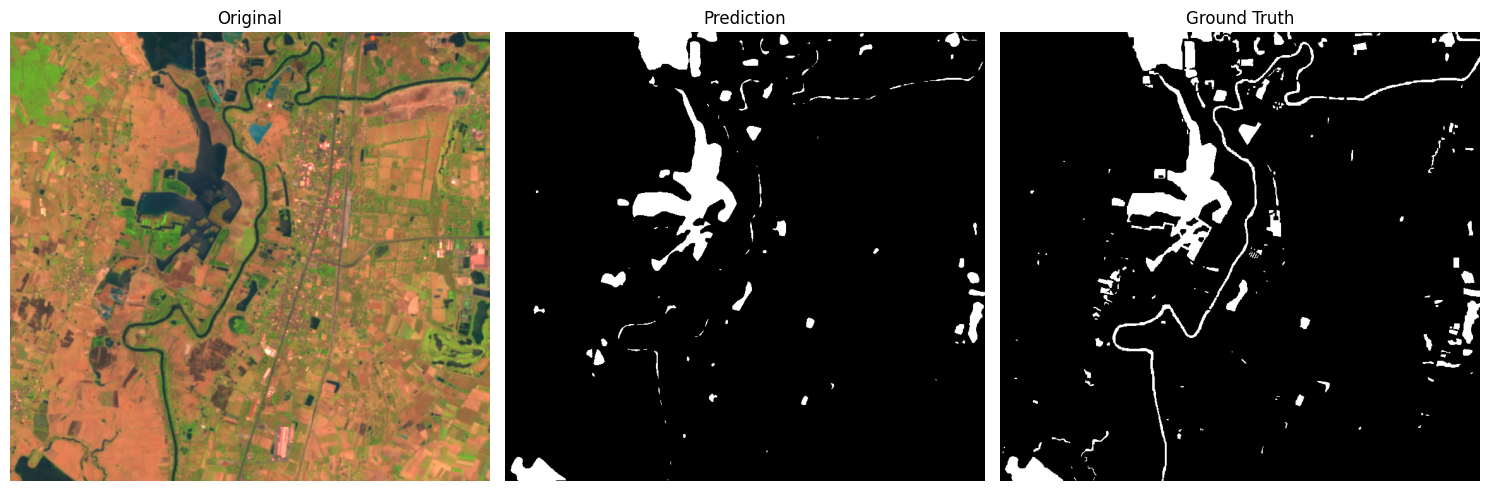

In [11]:
# Visualize inference outcomes ｜ 可视化推理结果（原图 / 预测 / 真值三联）
image_id = "S2A_L2A_20190318_N0211_R061"  # Change to other image id, e.g., S2B_L2A_20190620_N0212_R047 ｜ 可换别的场景
test_image_path = f"{data_dir}/dset-s2/val_scene/{image_id}_6Bands_S2.tif"       # 原图路径
ground_truth_path = f"{data_dir}/dset-s2/val_truth/{image_id}_S2_Truth.tif"      # 真值路径
prediction_path = f"{data_dir}/dset-s2/predictions/{image_id}_6Bands_S2_mask.tif"# 预测路径
save_path = f"lab5_figs/fig_q6_water_comparison.png" # 存盘位置（改到图目录）

fig = geoai.plot_prediction_comparison(              # 三联对比图
    original_image=test_image_path,                  # 原图
    prediction_image=prediction_path,                # 预测
    ground_truth_image=ground_truth_path,            # 真值
    titles=["Original", "Prediction", "Ground Truth"],           # 标题
    figsize=(15, 5),                                 # 画幅
    save_path=save_path,                             # 存盘
    show_plot=True,                                  # 同时显示
    indexes=[5, 4, 3],                               # 用 6 波段里的 5,4,3 假彩显示
    divider=5000,                                    # 亮度归一
)

**Q5**: Discuss the performance of the prediction in our example given above. Do so in reference to the ability of the prediction to resolve key features as compared to the ground truth (e.g. the river vs. the flood ponds). Explain why perfomance is varying in terms of both satellite data physical principles and the limitations of model and its training.

__ANSWER6_PLACEHOLDER__

Hopefully you can now see the difference that GeoAI makes to your workflow as compared to what we have gone through in the other labs. Their library is doing a lot of the plumbing and model management for you behind the scenes, allowing you to write faster and solve different problems rather than getting stuck in the weeds. We have only imported one library to accomplish something that before we were using 5 or 6 to do. This does come with drawbacks, choices have been made for you- but particuarly for quick prototyping this is a strong advantage.

Note that the GeoAI tutorial also shows you [how to gather satellite data](https://opengeoai.org/workshops/TNView_2025/#download-sentinel-2-imagery) from a [STAC catalgoue](https://stacspec.org/en). This is the alternative (to the GEE approach used to date) way to build satellite data stacks for use in your project. Might well be useful for you in your projects...

# Task 2:
This section of the lab we introduce object dection, bringing segmentation into our toolset. This approach leverages the power of deep learning to detect solar panels in aerial imagery, at the object level as opposed to the patch level we did in Lab 4.

Before starting this task, clear the cache and make sure your RAM is empty from Task 1, or you will crash the instance.

First, we download sample data once more, this time from the (pretty famous) [HuggingFace](https://huggingface.co/):

In [12]:
train_raster_url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/solar_panels_davis_ca.tif"        # 训练影像（加州 Davis 高分辨率航拍）
train_vector_url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/solar_panels_davis_ca.geojson"    # 训练标注（光伏板多边形）
test_raster_url = "https://huggingface.co/datasets/giswqs/geospatial/resolve/main/solar_panels_test_davis_ca.tif"    # 测试影像（模型没见过）

In [13]:
train_raster_path = geoai.download_file(train_raster_url, output_path="lab5_data/solar_panels_davis_ca.tif")         # 下训练影像
train_vector_path = geoai.download_file(train_vector_url, output_path="lab5_data/solar_panels_davis_ca.geojson")     # 下标注
test_raster_path = geoai.download_file(test_raster_url, output_path="lab5_data/solar_panels_test_davis_ca.tif")      # 下测试影像

Let's take a look at it:

In [14]:
geoai.view_vector_interactive(train_vector_path, tiles=train_raster_url)        # 交互式看标注叠在影像上（notebook 里可拖拽）

**（自加）静态版**：交互地图进不了报告，画一张静态的「标注叠影像」。

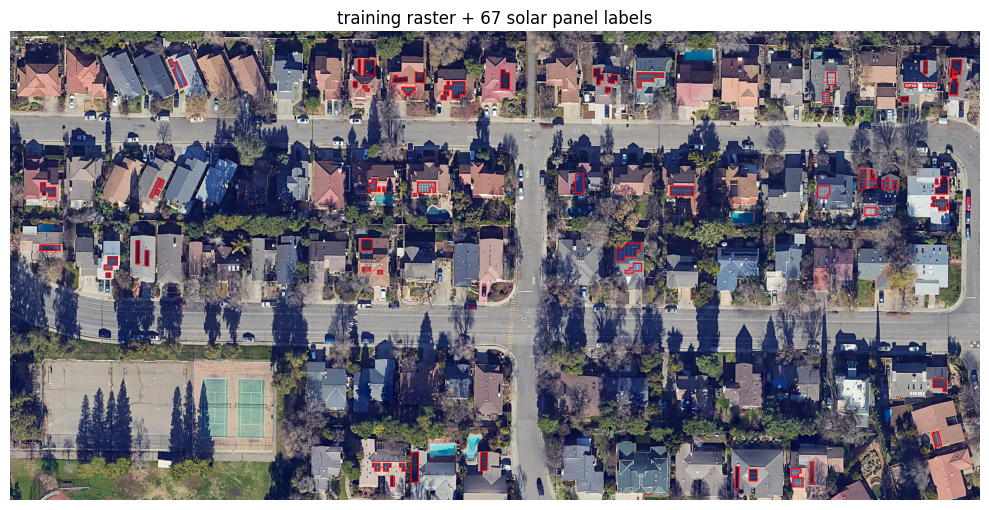

In [15]:
# ---- 静态版：训练影像 + 光伏标注叠加 ----
import rasterio                                      # 读 GeoTIFF
import geopandas as gpd                              # 读矢量
from rasterio.plot import show as rio_show           # rasterio 自带的画图助手
fig, ax = plt.subplots(figsize=(10, 10))             # 建图
with rasterio.open(train_raster_path) as src:        # 打开训练影像
    rio_show(src.read([1, 2, 3]), transform=src.transform, ax=ax)# RGB 显示（带地理坐标）
    crs_r = src.crs                                  # 记下影像坐标系
gdf_tr = gpd.read_file(train_vector_path)            # 读标注
if gdf_tr.crs != crs_r:                              # 坐标系不一致时
    gdf_tr = gdf_tr.to_crs(crs_r)                    # 重投影对齐
gdf_tr.boundary.plot(ax=ax, color='red', linewidth=0.8)          # 画多边形边界
ax.set_title(f'training raster + {len(gdf_tr)} solar panel labels')              # 标题带标注数
ax.axis('off')                                       # 关轴
plt.tight_layout(); plt.savefig('lab5_figs/fig_t2_labels.png', dpi=110, bbox_inches='tight'); plt.show()             # 存盘显示

Great, we have some high quality aerial data with well aligned vectors on top that accurately describe what a solar pannel is in this context.

Next, we generate our training data:

In [16]:
out_folder = "solar"                                 # 切片输出目录
tiles = geoai.export_geotiff_tiles(                  # 把训练影像+矢量标注切成片
    in_raster=train_raster_path,                     # 输入影像
    out_folder=out_folder,                           # 输出目录
    in_class_data=train_vector_path,                 # 矢量标注（会被栅格化成标签片）
    tile_size=512,                                   # 片大小
    stride=256,                                      # 步长 256 → 相邻重叠 256
    buffer_radius=0,                                 # 标注不外扩
)

'class' not found in vector data. Using default class ID 1.


Generating tiles:   0%|          | 0/312 [00:00<?, ?it/s]

Train the model:

In [17]:
geoai.train_segmentation_model(                      # 训练光伏分割模型
    images_dir=f"{out_folder}/images",               # 影像片
    labels_dir=f"{out_folder}/labels",               # 标签片
    output_dir=f"{out_folder}/models",               # 模型输出
    architecture="unet",                             # U-Net
    encoder_name="resnet34",                         # ResNet34
    encoder_weights="imagenet",                      # 预训练权重
    num_channels=3,                                  # 航拍 RGB 三通道
    num_classes=2,                                   # 背景/光伏
    batch_size=8,                                    # 批大小
    num_epochs=10,                                   # 10 轮
    learning_rate=1e-3,                              # 学习率
    val_split=0.2,                                   # 验证比例
    num_workers=0,                                   # Windows 用 0
)

Evaluate the model:

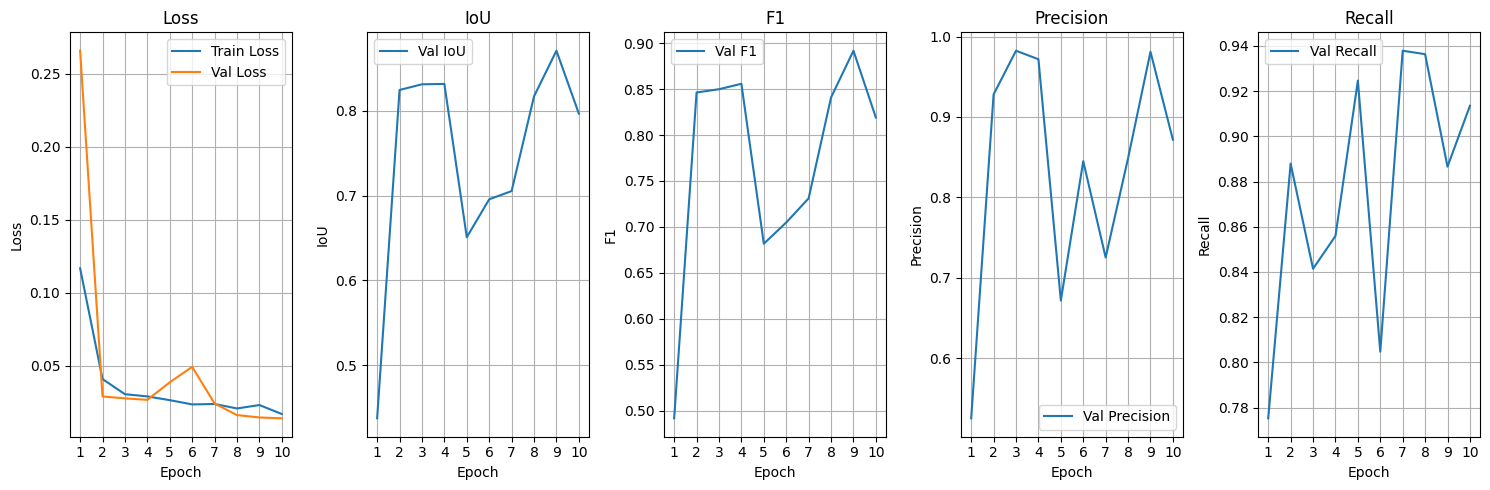

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.116783,0.265591,0.437385,0.491812,0.525105,0.775253
1,2,0.040986,0.029089,0.824524,0.846282,0.928014,0.887951
2,3,0.030627,0.027794,0.831232,0.849819,0.982376,0.841427
3,4,0.029114,0.026771,0.831655,0.855725,0.971760,0.855921
4,5,0.026557,0.038751,0.650932,0.681747,0.671607,0.924667
5,6,0.023639,0.049341,0.695620,0.704853,0.845021,0.804750
6,7,0.023934,0.024270,0.705329,0.731135,0.725187,0.937890
7,8,0.020879,0.016351,0.816991,0.840809,0.848636,0.936356
8,9,0.023217,0.014724,0.870825,0.891709,0.981074,0.886587
9,10,0.017073,0.014116,0.796677,0.819055,0.871687,0.913503


In [18]:
geoai.plot_performance_metrics(                      # 训练指标曲线
    history_path=f"{out_folder}/models/training_history.pth",    # 历史
    figsize=(15, 5),                                 # 画幅
    verbose=True,                                    # 打印数值
    save_path='lab5_figs/fig_t2_metrics.png',        # 自加：存盘
)

Run inference (apply it to never seen before data):

In [19]:
masks_path = "lab5_data/solar_panels_prediction.tif" # 预测掩膜输出位置
model_path = f"{out_folder}/models/best_model.pth"   # 最优权重

geoai.semantic_segmentation(                         # 对测试影像推理
    input_path=test_raster_path,                     # 没见过的测试影像
    output_path=masks_path,                          # 输出掩膜
    model_path=model_path,                           # 模型
    architecture="unet",                             # 与训练一致
    encoder_name="resnet34",                         # 与训练一致
    num_channels=3,                                  # 与训练一致
    num_classes=2,                                   # 与训练一致
    window_size=512,                                 # 滑窗
    overlap=256,                                     # 重叠
    batch_size=8,                                    # 批大小
)

  0%|          | 0/209 [00:00<?, ?it/s]

Vectorize the masks we have generated:

In [20]:
output_path = "lab5_data/solar_panels_prediction.geojson"        # 矢量化输出位置
gdf = geoai.orthogonalize(masks_path, output_path, epsilon=2)    # 栅格掩膜 → 正交化多边形（光伏板都是矩形）

Converting features:   0%|          | 0/55 [00:00<?, ?shape/s]

**Q6**: what is this vectorize operation doing to the raster mask output by the model and why are we doing so?

__ANSWER5_PLACEHOLDER__

Validate for ourselves that the predictions output has things in it:

In [21]:
import geopandas as gpd                              # 矢量处理

gdf = gpd.read_file(output_path)                     # 读回矢量化结果
print(f"Number of polygons: {len(gdf)}")             # 多边形数量
print(gdf.head())                                    # 前几行

Number of polygons: 41
   value                                           geometry
0      1  POLYGON ((-13555473.342 4657750.922, -13555473...
1      1  POLYGON ((-13555660.789 4657748.16, -13555660....
2      1  POLYGON ((-13555670.269 4657745.697, -13555670...
3      1  POLYGON ((-13555692.888 4657745.473, -13555692...
4      1  POLYGON ((-13555661.162 4657742.86, -13555661....


Finally we will visualize the results, and here I step away from GeoAI and write our own function for mapping the output in order to have more control over it (you might have to zoom in quite a way to see the predictions...):

In [22]:
import geopandas as gpd                              # 矢量
import geemap                                        # 地图控件
import math                                          # 算缩放级别

import ee                                            # Earth Engine（此格其实只有仪式作用，底图走 xyz 瓦片）
EE_PROJECT = os.environ.get('EE_PROJECT', 'geog761-ai')          # 项目名：本机用环境变量覆盖
try:                                                 # 免弹窗初始化；失败就跳过（Kaggle 等无凭据环境不能调 Authenticate——会卡住等回调）
    ee.Initialize(project=EE_PROJECT)                # 本机走 ADC / Colab 已授权时直接过
except Exception as _e:                              # 没有凭据
    print('Earth Engine init skipped:', type(_e).__name__)       # 说明一声，不影响本格后续（geemap 底图不依赖 EE）


def plot_results_interactive(vector_path, raster_path, basemap="SATELLITE"):
    """
    Display vector predictions over a raster with automatic zoom to fit extent.
    Reprojects to EPSG:4326 if needed.
    """                                              # 把预测多边形叠在影像上交互显示
    # Load vector and set CRS correctly ｜ 读矢量并处理坐标系
    gdf = gpd.read_file(vector_path)                 # 读文件
    if gdf.empty:                                    # 空的就退出
        print("No features found in vector file.")   # 提示
        return                                       # 返回

    # If CRS is missing, set it manually (based on your file) ｜ 缺坐标系就手动设
    if gdf.crs is None:                              # 没有 CRS
        print("No CRS detected. Assuming EPSG:3857 (Web Mercator).")             # 提示
        gdf = gdf.set_crs("EPSG:3857")               # 按 Web Mercator 处理

    # If not already in EPSG:4326, reproject for web display ｜ 转成经纬度便于網頁显示
    if gdf.crs.to_string() != "EPSG:4326":           # 不是 4326
        gdf = gdf.to_crs("EPSG:4326")                # 重投影

    # Get extent ｜ 取范围
    minx, miny, maxx, maxy = gdf.total_bounds        # 外包框
    center_lon = (minx + maxx) / 2                   # 中心经度
    center_lat = (miny + maxy) / 2                   # 中心纬度

    # Calculate zoom based on extent size ｜ 按范围大小算缩放级别
    lon_span = maxx - minx                           # 经度跨度
    lat_span = maxy - miny                           # 纬度跨度
    max_span = max(lon_span, lat_span)               # 取大者
    if max_span < 1e-6:                              # 范围极小
        zoom = 19                                    # 拉满
    else:                                            # 一般情况
        zoom = int(math.floor(8 - math.log(max_span) / math.log(2)))             # 对数换算
        zoom = max(1, min(zoom, 20))                 # 夹在 1-20

    # Create map ｜ 建地图
    m = geemap.Map()                                 # 地图控件
    m.add_basemap(basemap)                           # 加卫星底图
    m.set_center(center_lon, center_lat, zoom=zoom)  # 定位

    # Save a temporary reprojected file so geemap can read it ｜ 存个临时重投影文件给 geemap 读
    tmp_path = "lab5_data/reprojected.geojson"       # Windows 没有 /tmp，放本地目录
    gdf.to_file(tmp_path, driver="GeoJSON")          # 写文件

    # Add layers ｜ 叠图层
    m.add_raster(raster_path, layer_name="Raster", opacity=0.8)  # 影像
    m.add_vector(tmp_path, style={"color": "red", "fillOpacity": 0.2}, layer_name="Predictions") # 预测多边形

    return m                                         # 返回地图

# Example usage: ｜ 示例（批处理/无显示环境里本地瓦片服务可能起不来，失败不挡流程）
try:                                                 # 保护壳
    m = plot_results_interactive(output_path, test_raster_path)  # 交互地图
except Exception as _e:                              # 起不来就跳过
    m = None; print('interactive map skipped:', type(_e).__name__, _e)           # 说明原因
m                                                    # 显示（跳过时无输出）

Earth Engine init skipped: EEException


To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=6nMU8NfxBnt6dNQ17pjiEvhh63kOeyUrV_Cj16pKaIE&tc=Jmg7M6JsHhDDCGVOqUAEUvYKkfTjjdcij6H34a-0bAg&cc=WRiUcJp4hh1VZnW1lJhD3jcFfLR3Hk4x4-KdZAVW0Jc

The authorization workflow will generate a code, which you should paste in the box below.
interactive map skipped: StdinNotImplementedError raw_input was called, but this frontend does not support input requests.


**Q7** Exercise: using the code given above, the linked materials and any other sources you can find, improve the output of the model in order to better segment solar pannels in the given data. In your answer:
*   Produce a publication quality figure of the resulting output.
*   Write a paragraph that desbribes the steps you took and why.

Make sure to reference any materials used.



**（自加）Q7 实现**：三个改进一起上，目标是更完整、更干净的光伏分割。
1. **更多训练样本**：切片 stride 从 256 收到 **128**（相邻重叠更大，切出约 4 倍的片），模型见到更多光伏板的平移变体
2. **训练更充分**：epochs 10→**30**，挂 `early_stopping_patience=8` 防过拟合白跑
3. **后处理提纯**：`orthogonalize` 的 `min_area` 从 10 提到 **40 m²**（丢掉噪点小斑），`epsilon=2` 保持
参考：GeoAI 文档 opengeoai.org、segmentation-models-pytorch 文档。

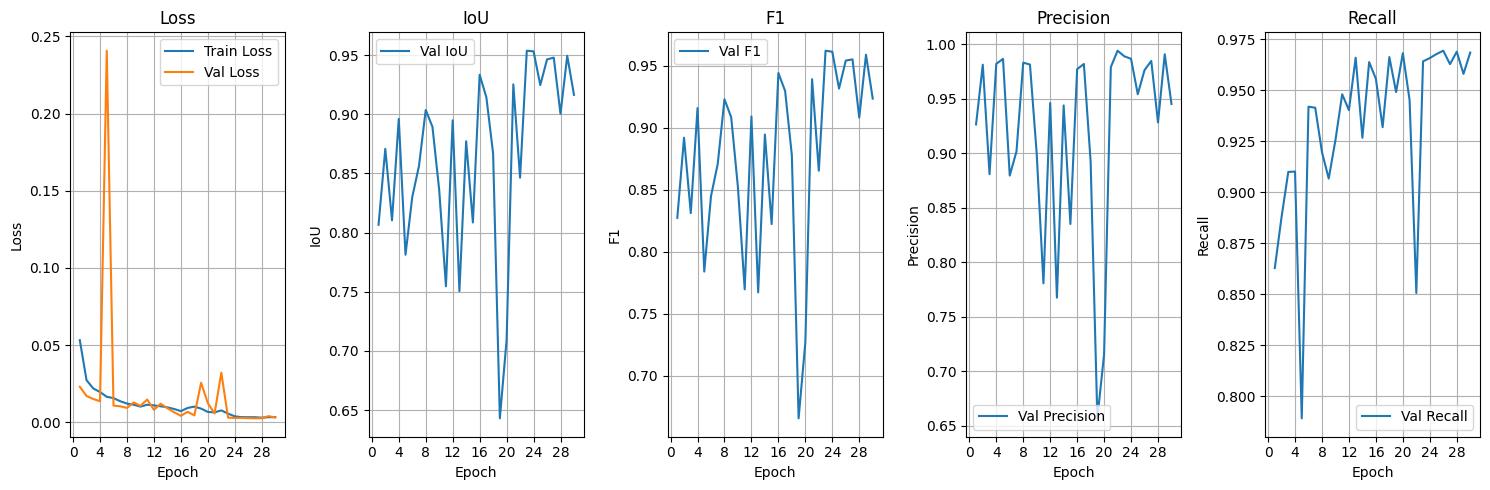

,epoch,train_loss,val_loss,val_iou,val_f1,val_precision,val_recall
0,1,0.053229,0.023015,0.806565,0.827298,0.926304,0.862872
1,2,0.027307,0.017067,0.870744,0.891860,0.981083,0.887834
2,3,0.021921,0.015082,0.810354,0.831131,0.880689,0.910004
3,4,0.019639,0.013655,0.896069,0.915741,0.981844,0.910216
4,5,0.016531,0.240781,0.781241,0.784038,0.986396,0.789130
5,6,0.015668,0.010809,0.829922,0.844769,0.879465,0.942023
6,7,0.013652,0.010364,0.856322,0.870763,0.901538,0.941529
7,8,0.012133,0.009330,0.903569,0.922866,0.982959,0.919730
8,9,0.011389,0.012883,0.889372,0.908297,0.981230,0.906751
9,10,0.010158,0.010620,0.835973,0.851794,0.899619,0.925626


In [23]:
# ---- Q7：改进版训练 ----
out2 = "solar_v2"                                    # 改进版输出目录
tiles2 = geoai.export_geotiff_tiles(                 # 重新切片：更小步长
    in_raster=train_raster_path,                     # 训练影像
    out_folder=out2,                                 # 输出
    in_class_data=train_vector_path,                 # 标注
    tile_size=512,                                   # 片大小不变
    stride=128,                                      # ← 步长 256→128：约 4 倍训练片
    buffer_radius=0,                                 # 不外扩
    quiet=True,                                      # 不刷屏
)
geoai.train_segmentation_model(                      # 重训
    images_dir=f"{out2}/images",                     # 影像片
    labels_dir=f"{out2}/labels",                     # 标签片
    output_dir=f"{out2}/models",                     # 模型输出
    architecture="unet",                             # U-Net
    encoder_name="resnet34",                         # ResNet34
    encoder_weights="imagenet",                      # 预训练
    num_channels=3,                                  # RGB
    num_classes=2,                                   # 两类
    batch_size=8,                                    # 批大小
    num_epochs=30,                                   # ← 10→30 轮
    learning_rate=1e-3,                              # 学习率不变
    val_split=0.2,                                   # 验证比例
    early_stopping_patience=8,                       # ← 8 轮不进步就停
    num_workers=0,                                   # Windows 用 0
)
geoai.plot_performance_metrics(                      # 改进版指标曲线
    history_path=f"{out2}/models/training_history.pth",          # 历史
    figsize=(15, 5),                                 # 画幅
    verbose=True,                                    # 打印
    save_path='lab5_figs/fig_q7_metrics_v2.png',     # 存盘
)

In [24]:
# ---- Q7：改进版推理 + 提纯矢量化 ----
masks2 = "lab5_data/solar_panels_prediction_v2.tif"  # 改进版掩膜
geoai.semantic_segmentation(                         # 推理
    input_path=test_raster_path,                     # 测试影像
    output_path=masks2,                              # 输出
    model_path=f"{out2}/models/best_model.pth",      # 改进版权重
    architecture="unet",                             # 一致
    encoder_name="resnet34",                         # 一致
    num_channels=3,                                  # 一致
    num_classes=2,                                   # 一致
    window_size=512,                                 # 滑窗
    overlap=256,                                     # 重叠
    batch_size=8,                                    # 批大小
)
out_vec2 = "lab5_data/solar_panels_prediction_v2.geojson"        # 改进版矢量
gdf2 = geoai.orthogonalize(masks2, out_vec2, epsilon=2, min_area=40)             # ← min_area 10→40 m²：丢噪点
print(f'v1 polygons: {len(gpd.read_file(output_path))}  ->  v2 polygons: {len(gdf2)}')           # 前后数量对比

  0%|          | 0/209 [00:00<?, ?it/s]

Converting features:   0%|          | 0/68 [00:00<?, ?shape/s]

v1 polygons: 41  ->  v2 polygons: 55


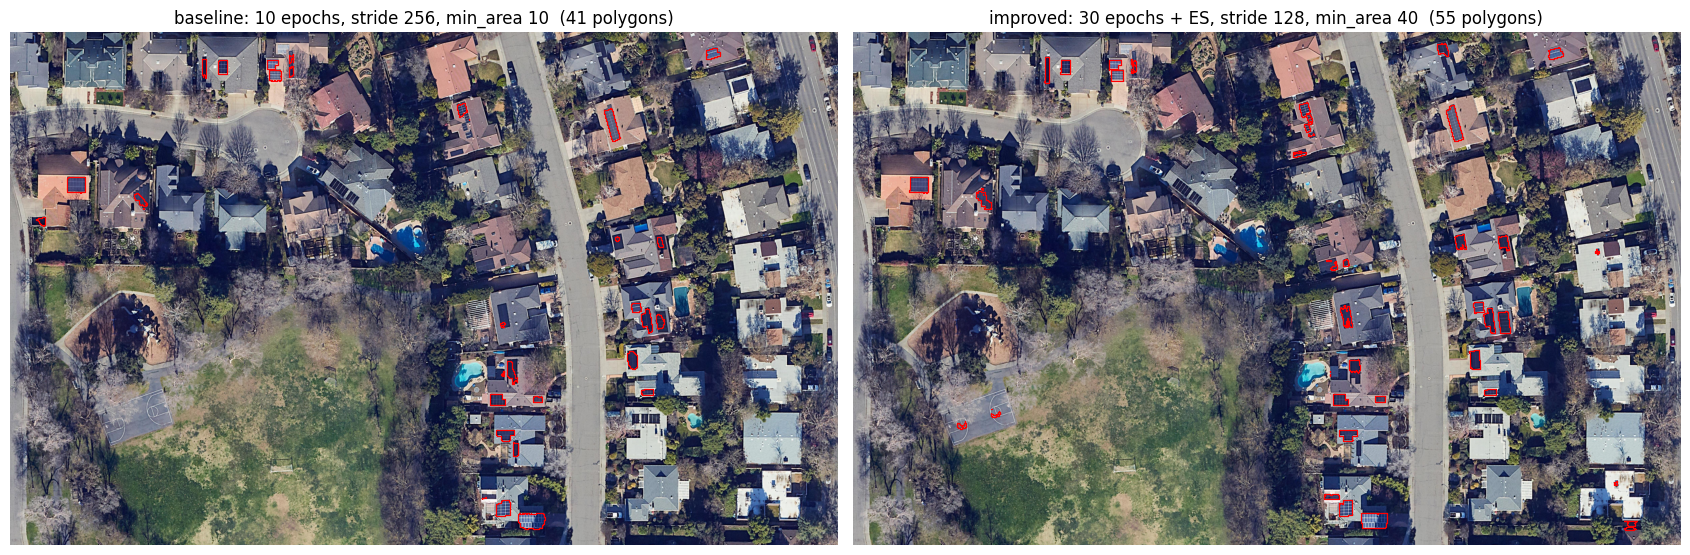

In [25]:
# ---- Q7 成果图：v1 vs v2 预测多边形叠在测试影像上 ----
with rasterio.open(test_raster_path) as src:         # 打开测试影像
    img_rgb = src.read([1, 2, 3])                    # RGB
    tr = src.transform; crs_t = src.crs              # 地理参考
fig, axes = plt.subplots(1, 2, figsize=(17, 9))      # 并排两图
for ax, vec, ttl in [(axes[0], output_path, 'baseline: 10 epochs, stride 256, min_area 10'),     # 左：基线
                     (axes[1], out_vec2, 'improved: 30 epochs + ES, stride 128, min_area 40')]:  # 右：改进
    rio_show(img_rgb, transform=tr, ax=ax)           # 底图
    g = gpd.read_file(vec)                           # 读多边形
    if g.crs != crs_t: g = g.to_crs(crs_t)           # 对齐坐标系
    g.boundary.plot(ax=ax, color='red', linewidth=0.9)           # 画边界
    ax.set_title(f'{ttl}  ({len(g)} polygons)')      # 标题带数量
    ax.axis('off')                                   # 关轴
plt.tight_layout()                                   # 收紧
plt.savefig('lab5_figs/fig_q7_solar_compare.png', dpi=110, bbox_inches='tight')  # 存盘（Q7 成果图）
plt.show()                                           # 显示

__ANSWER7_PLACEHOLDER__